In [121]:
import  pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [122]:
#loading the data
df = pd.read_csv('../csv/game_lineups.csv')

df

,game_lineups_id,game_id,club_id,type,number,player_id,player_name,team_captain,position
0,77b0f371923e0c8bdf050a1e269faaac,3606208,338,starting_lineup,89,419061,Vladyslav Supryaga,0,Centre-Forward
1,cb6eeedb9f728570615d37b6fe7facaf,3606208,338,starting_lineup,10,368611,Mykola Shaparenko,0,Central Midfield
2,8e63d5f47aac2bdb0e54f5481986e104,3606208,338,starting_lineup,5,124182,Sergiy Sydorchuk,1,Defensive Midfield
3,ea4a96d8be410f2d646cf095c4faae7f,3606208,338,starting_lineup,94,181118,Tomasz Kedziora,0,Right-Back
4,e6abe553801b09bc623c3deb96acba17,3606208,338,starting_lineup,16,404842,Vitaliy Mykolenko,0,Left-Back
...,...,...,...,...,...,...,...,...,...
119128,f4e6a6b2e3d24d12290c6ce4168e1bdb,4228114,46889,substitutes,3,1200869,Thomas Chambers,0,Left-Back
119129,7a78814a66c59c79e8d40c8669a67d3f,4228114,46889,substitutes,5,1203716,Mohammed-Idris Oshilaja,0,Defender
119130,09cc07767ce441b4de4a76c102fd17d5,4228114,46889,substitutes,13,1200870,Max Ovenden,0,Goalkeeper
119131,3c259f1849421af021aba3e84a4da8de,4228114,46889,substitutes,12,550816,Julien Anau,0,Attacking Midfield


### Data Exploration
The dataset contains 119133 rows and 9 columns:
- `game_lineups_id`: unique identifier for each game lineup
- `game_id`: unique identifier for each game in which the lineup was used
- `club_id`: unique identifier for the club
- `type`: type of lineup (starting or substitute)
- `number`: player number
- `player_id`: unique identifier for the player
- `player_name`: name of the player
- `team_captain`: boolean value indicating if the player is the team captain
- `position`: position of the player

In [123]:
#checking for duplicated
print(f'Duplicated entries: {df.duplicated().sum()}')

#checking for missing values
print(f'Missing values: {df.isna().sum()}')

Duplicated entries: 0
Missing values: game_lineups_id    0
game_id            0
club_id            0
type               0
number             0
player_id          0
player_name        0
team_captain       0
position           0
dtype: int64


### Data Cleaning
The data frame is clean, no missing values or duplicated entries were found.

### Data Analysis

In [124]:
games_count = df['game_id'].nunique()
clubs_count = df['club_id'].nunique()
print(f'The dataset contains data for {games_count} games and {clubs_count} clubs.')

df.dtypes

The dataset contains data for 2917 games and 1127 clubs.


game_lineups_id    object
game_id             int64
club_id             int64
type               object
number             object
player_id           int64
player_name        object
team_captain        int64
position           object
dtype: object

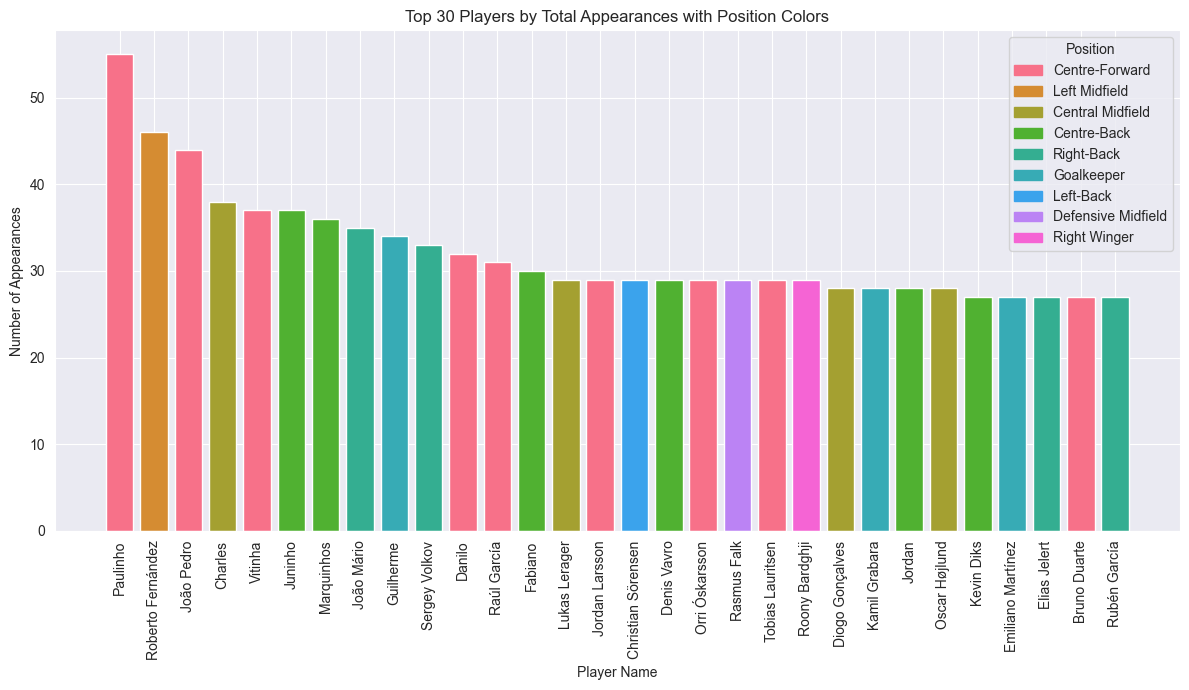

In [125]:
#Counting the number of appearances for each player
player_appearances_with_position = df.groupby(['player_name', 'position']).size().reset_index(name='appearances')

# Get the total number of appearances for each player
player_total_appearances = player_appearances_with_position.groupby('player_name')['appearances'].sum().reset_index()

# Find the most frequent position for each player
player_most_frequent_position = player_appearances_with_position.loc[
    player_appearances_with_position.groupby('player_name')['appearances'].idxmax()][['player_name', 'position']]

# Merge total appearances with most frequent position
player_summary = player_total_appearances.merge(player_most_frequent_position, on='player_name')

# Sort by total appearances and get the top 30 players
top_players = player_summary.sort_values(by='appearances', ascending=False).head(30)

# Assign a unique color for each position
unique_positions = top_players['position'].unique()
palette = sns.color_palette("husl", len(unique_positions))  # Generate colors for positions
color_map = dict(zip(unique_positions, palette))  # Map positions to colors

# Map the colors for each player based on their most frequent position
colors = top_players['position'].map(color_map)

# Plot the top players by total appearances with color for their most frequent position
plt.figure(figsize=(12, 7))
plt.bar(top_players['player_name'], top_players['appearances'], color=colors)
plt.title('Top 30 Players by Total Appearances with Position Colors')
plt.xlabel('Player Name')
plt.ylabel('Number of Appearances')
plt.xticks(rotation=90, ha='center')

# Add a legend to explain the colors
handles = [plt.Rectangle((0,0),1,1, color=color_map[position]) for position in unique_positions]
plt.legend(handles, unique_positions, title='Position')

plt.tight_layout()
plt.show()

# Top 30 Players by Total Appearances with Position Colors

The above bar chart illustrates the top 30 players based on the number of appearances in the lineups. Each bar represents a player, and the height corresponds to the total number of appearances across all games.

To provide better context, the bars are color-coded according to the players' positions on the field. The legend in the top right corner shows the mapping between the positions and the associated colors.

The positions included in this visualization are:
- Centre-Forward
- Left Midfield
- Central Midfield
- Centre-Back
- Right-Back
- Goalkeeper
- Left-Back
- Defensive Midfield
- Right Winger

This visualization helps identify not only the players who have consistently featured in games but also the diversity of positions that make up the top appearances.


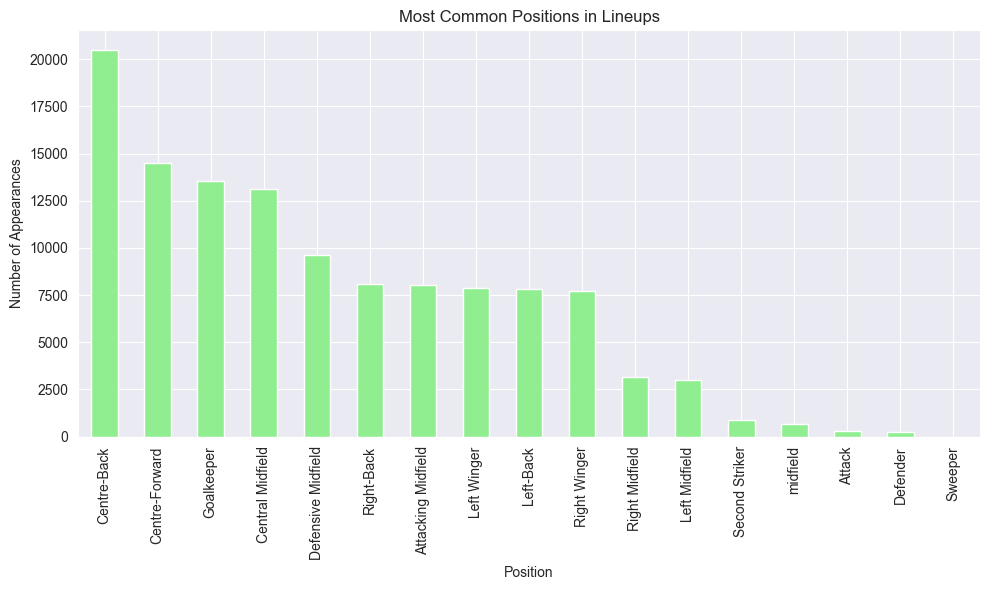

In [126]:
# Count how often each position appears in lineups
position_counts = df['position'].value_counts()

# Plot the most common positions
plt.figure(figsize=(10, 6))
position_counts.plot(kind='bar', color='lightgreen')
plt.title('Most Common Positions in Lineups')
plt.xlabel('Position')
plt.ylabel('Number of Appearances')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Most Common Positions in Lineups

The bar chart above shows the distribution of player appearances by position in football lineups. The positions are sorted based on the number of appearances across all games.

- **Centre-Back** has the highest number of appearances, making it the most common position, with over 20,000 appearances.
- Other prominent positions include **Centre-Forward**, **Goalkeeper**, and **Central Midfield**, all with a significant number of appearances.
- The visualization also highlights other positions like **Right-Back**, **Left-Back**, **Right Winger**, and more, each contributing to the overall lineup structure.

This analysis provides insights into the most frequently used player roles in the team formations, indicating tactical tendencies across various teams and games.


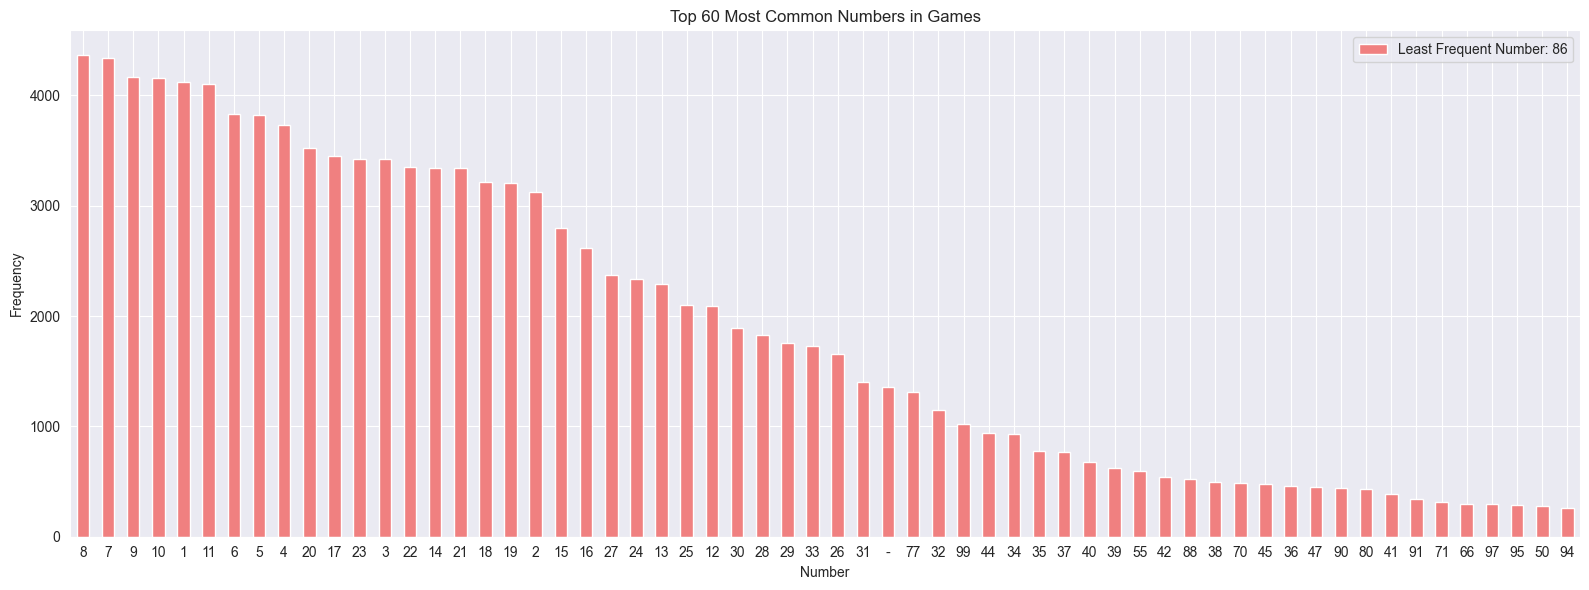

In [127]:
# Count how often each number appears in games
number_counts = df['number'].value_counts()

# Sort the numbers by frequency
number_counts = number_counts.sort_values(ascending=False)

# Plot the most common numbers
plt.figure(figsize=(16, 6))
top_60_counts = number_counts.head(60)  # Store the top 60 counts for later use
bars = top_60_counts.plot(kind='bar', color='lightcoral')
plt.title('Top 60 Most Common Numbers in Games')
plt.xlabel('Number')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.tight_layout()

# Find the least frequent number across all counts
least_frequent_count = number_counts.iloc[-1]  # Get the frequency of the least common number
least_frequent_number = number_counts.index[-1]  # Get the least frequent number itself

# Create a legend entry with a descriptive label
legend_label = f'Least Frequent Number: {least_frequent_number}'
plt.legend([legend_label], loc='upper right')  # Pass the legend as a list

plt.show()

### Top 60 Most Common Numbers in Games
The plot above shows the distribution of player numbers in football games, highlighting the top 60 most common numbers used by players across various lineups.
- We have that the number 8 is the one that appears the most in the games.
- Other popular numbers include 1, 6, 7, 10, 11, 9, and 5, each representing a significant portion of the total appearances.
- The less popular number is 86.

This analysis provides insights into the preferred numbering choices for players in football lineups, showcasing the distribution of numbers across different games and teams.

In [128]:
# Saving the df
df.to_csv('../cleaned_csv/game_lineups_cleaned.csv', index=False)